# Model hierarchy analysis: base models, derivatives, and who publishes them

**Questions (from the Oct 22 2026 meeting)**
1. Of the top 313 most-downloaded models on Hugging Face, which are base models and which are derivatives? Who publishes them?
2. Across the full metadata pull, whose base models do derivatives trace back to? Do a few large labs have more reach than their own uploads suggest?

All logic lives in `model_lineage_analysis.py`. This notebook runs it and walks through the definitions, method, results, and caveats. The full run takes about 30 seconds. It needs the LFS data (`git lfs pull`), and `raw_data/models_popular.jsonl` if available.

## Definitions

| Term | Meaning in this analysis |
|---|---|
| **Base model** | A model trained from scratch by its developer, e.g. `Qwen/Qwen3-8B` or `google-bert/bert-base-uncased`. |
| **Derivative** | A model made by starting from another model's weights instead of training from scratch: a fine-tune, quantized copy, adapter, merge or pruned copy (see below). A derivative can itself be the parent of further derivatives. |
| **Parent** | The model a derivative was built from, as declared in its `base_model` field or added from `undeclared_parents.csv`. |
| **Derivation** | The act of building one model from another. A **derivation chain** is the sequence of parent links from a derivative up to its root, e.g. `GGUF copy → fine-tune → Qwen3-8B`. |
| **Root (root base model)** | The model at the top of a chain: the first model reached that lists no parent. It's usually a base model, but not always (see caveat 1). |
| **Generation** | How many links a derivative is below its root. A fine-tune of Qwen is generation 1; a GGUF of that fine-tune is generation 2. All generations count toward the root. |
| **Derivatives rooted in X** | Every derivative, at any generation, whose chain ends at one of X's models. |
| **Share of derivatives** | Derivatives rooted in a group ÷ all declared derivatives. |
| **Derivative downloads** | The sum of the **derivatives' own** all-time downloads for chains ending at a group's models. It does **not** include the root model's own downloads. |
| **Share of models published** | Models a group itself uploads ÷ all models in the metadata (≥100 downloads). Comparing this with the share of derivatives shows reach beyond the group's own uploads. |
| **Publisher** | The Hugging Face account that uploaded a model (the part before the `/`). |
| **Front account** | An account that publishes a company's weights under another name, e.g. a researcher's personal account or a re-upload. These are re-attributed in `publisher_overrides.csv` only with a public source. |
| **Big Tech** | A publicly listed tech company with a market cap ≥ $100B (CompaniesMarketCap, fetched 2026-11-07). |
| **Frontier developer** | A developer that passes **either** frontier test. **Capability test:** it released a model within 5 points of the best model available at that time on Epoch AI's Capabilities Index (ECI), i.e. roughly 3–4 months behind the leader. **Compute test:** it trained a model with > 10^25 FLOP (EU AI Act Art. 51(2)). |
| **ECI (Epoch Capabilities Index)** | Epoch AI's composite score that combines 50+ benchmarks into one capability scale. Higher = more capable. The frontier moved about 16–18 ECI points a year in 2025–26. |
| **FLOP** | Floating-point operations: the total arithmetic used to train a model, and the standard yardstick for training scale. 10^25 = 10 million billion billion. |
| **Repackager** | An account whose models are mostly quantized, converted or re-hosted copies of others' models (e.g. mradermacher, bartowski, LM Studio). |
| **Top 313** | The 313 most-downloaded models on the Hub (top 0.01% of ~3.1M), which together get 68.7% of all downloads. |

### Kinds of derivative (the Hub's `base_model_relation`)

| Kind | What was done to the parent | Same weights? |
|---|---|---|
| **finetune** | The parent's weights were trained further on new data or for a new task. | Changed |
| **quantized** | The parent's numbers were stored at lower precision (e.g. 16-bit → 4-bit GGUF), so it's smaller and faster but behaves the same. Usually no new training. | Same model, compressed |
| **adapter** | A small add-on (usually LoRA) is trained and sits on top of the parent. The add-on is useless without the parent. | Parent unchanged, plus a small add-on |
| **merge** | Two or more models' weights are blended into one. | Mixed |
| *pruned* | Layers removed from the parent. This isn't a Hub category; it's used only for a documented correction. | Subset |

The Hub fills in this label automatically, and it can be wrong. For example, it labels `all-MiniLM-L6-v2` as "quantized" because the repo bundles ONNX exports, but it's really a fine-tune.

## Method

1. **Parent links.** Each model's parent comes from the self-reported `base_model` field (`cardData.base_model` and `base_model:<relation>:<parent>` tags). A model with several parents follows its first listed parent.
2. **Tracing to the root.** Each derivative follows its parent links upward until it reaches a model with no listed parent. That model is the root.
3. **Publisher type.** Accounts are hand-labeled in `model_lineage/author_types.csv`. Company accounts are labeled `Company` with their `org`. Unlisted accounts are counted as "Unlabeled (long tail)".
4. **Splitting companies with two questions** (`model_lineage/org_classification.csv`, every row with its evidence):
   - **Is it Big Tech? (size).** The company must be publicly listed, with a market cap of at least $100B (CompaniesMarketCap, fetched 2026-11-07).
   - **Is it a frontier developer?** It must pass either frontier test (see *Defining "frontier"* below):
     - **Capability test (primary).** It released a model within 5 ECI points of the best model available at that time, counting models released since 2024. Source: `model_lineage/eci_scores_snapshot.csv`, Epoch AI, accessed 2026-11-08.
     - **Compute test.** It trained a model with more than 10^25 FLOP (EU AI Act Art. 51(2)), per Epoch AI's *Large-Scale AI Models* compute field.
   - The two tests give four groups: Big Tech + frontier developer / Big Tech, not frontier / Frontier developer, not Big Tech / Other companies & startups. **The figures merge the first three into "Big Tech or frontier developer"** (passes either test); the tables keep the four-way split.
5. **Documented corrections**, each with a public source:
   - `undeclared_parents.csv` adds parent links the model card states but the metadata omits.
   - `publisher_overrides.csv` re-attributes accounts or models that publish a company's weights.
   - The analysis also keeps a metadata-only baseline, so the effect of the corrections is visible.

In [1]:
import pandas as pd
from IPython.display import Image, display
import model_lineage_analysis as mla

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", None)  # show full evidence text
res = mla.run(verbose=False)
models, kids = res["models"], res["kids"]
print(f"Models with metadata (>=100 downloads): {len(models):,}")
print(f"Declared derivatives traced to a root:  {len(kids):,} ({len(kids) / len(models):.1%} of models)")

Models with metadata (>=100 downloads): 122,749
Declared derivatives traced to a root:  19,167 (15.6% of models)


## Defining "frontier"

The EU AI Act doesn't define frontier by compute alone. Article 51(2) presumes "high-impact capabilities" above 10^25 training FLOP, but **Annex XIII** lists seven criteria the Commission can use to designate a model:

1. Number of parameters
2. Size or quality of the training data (e.g. tokens)
3. Training compute (FLOP)
4. Input and output modalities
5. **Benchmarks and evaluations of capabilities**
6. Market reach (presumed at 10,000 registered EU business users)
7. Number of registered end users

**We use two of them: capability evaluations (5) and training compute (3).**
- **Capability is the primary test.** It measures what a model can do rather than what was spent, so it catches labs that reach the frontier with less compute.
- **Compute is kept as a second route.** Several developers have no models on Epoch's capability leaderboard (ByteDance, Huawei), and compute is the EU's bright-line number.
- **We don't use reach (6–7).** Downloads and derivatives are what this analysis measures, so defining "frontier" by reach would be circular.
- **We don't use parameter count or data size (1–2).** They're poorly disclosed and say little on their own.

**The capability rule.** For every model on Epoch's Capabilities Index (ECI), we compute its gap to the best model released on or before its release date. A developer passes if any model released since 2024 is within 5 ECI points of that frontier. The frontier moved about 16–18 ECI points a year in 2025–26, so 5 points is roughly 3–4 months behind the leader. Models before 2024 are excluded because the leaderboard has few entries from then, which would make early gaps look small.

In [2]:
cols = ["big_tech", "capability_frontier", "compute_frontier", "frontier", "capability_evidence", "compute_evidence"]
res["orgs"][cols]

,big_tech,capability_frontier,compute_frontier,frontier,capability_evidence,compute_evidence
org,,,,,,
Google,y,y,y,y,"best: Gemini 2.5 Pro (Mar 2025) (2025-03), ECI 143.9 vs frontier 143.9 (gap 0.0)","Gemini 1.0 Ultra, 5.0e25 FLOP (2023-12) — source: https://epoch.ai/data/large_scale_ai_models.csv"
Meta,y,y,y,y,"best: Llama 3.1-405B (2024-07), ECI 127.9 vs frontier 130.0 (gap 2.1)","Llama 3.1-405B, 3.8e25 FLOP (2024-07) — source: https://epoch.ai/data/large_scale_ai_models.csv"
Microsoft,y,n,y,y,"closest: Phi-4 (2024-12), ECI 129.2 vs frontier 135.4 (gap 6.2)","MAI-Base-2, 2.4e25 FLOP (2026-10) — source: https://epoch.ai/data/large_scale_ai_models.csv"
NVIDIA,y,n,y,y,"closest: Nemotron 3 Ultra (2026-06), ECI 147.1 vs frontier 162.7 (gap 15.6)","Nemotron-4 340B, 1.8e25 FLOP (2024-06) — source: https://epoch.ai/data/large_scale_ai_models.csv"
Alibaba,y,y,y,y,"best: Qwen3-235B-A22B-Thinking (Jul 2025) (2025-07), ECI 143.2 vs frontier 147.4 (gap 4.2)","Qwen3-Max, 1.512e25 FLOP (2025-09; Epoch marks estimate speculative) — source: https://epoch.ai/data/large_scale_ai_models.csv"
Amazon,y,n,n,n,no model on Epoch's ECI leaderboard,no model ≥1e25 in Epoch's compute field — source: https://epoch.ai/data/large_scale_ai_models.csv
Apple,y,n,n,n,no model on Epoch's ECI leaderboard,no model ≥1e25 in Epoch's compute field — source: https://epoch.ai/data/large_scale_ai_models.csv
AMD,y,n,n,n,no model on Epoch's ECI leaderboard,no model ≥1e25 in Epoch's compute field — source: https://epoch.ai/data/large_scale_ai_models.csv
Intel,y,n,n,n,no model on Epoch's ECI leaderboard,no model ≥1e25 in Epoch's compute field — source: https://epoch.ai/data/large_scale_ai_models.csv


## 1. The top 313 most-downloaded models

In [3]:
top = res["top"]
print(top["lineage"].value_counts().to_string())
res["top_by_type"].style.format({"downloads": "{:,.0f}", "download_share": "{:.1%}"})

lineage
No declared parent        262
Declared derivative        48
Not in pulled metadata      3


,models,downloads,download_share
publisher_type,,,
Big Tech + frontier developer,110,"16,679,407,854",32.0%
"Big Tech, not frontier",13,"1,361,210,089",2.6%
"Frontier developer, not Big Tech",18,"4,294,879,135",8.2%
Other companies & startups,21,"2,828,464,378",5.4%
Repackagers (quantize/convert/re-host),16,"878,626,037",1.7%
Academic & nonprofit,42,"6,860,359,942",13.2%
Individuals & community,48,"5,661,561,197",10.9%
Open-source projects & Hugging Face,42,"13,371,638,325",25.7%
Needs review,3,"162,746,776",0.3%


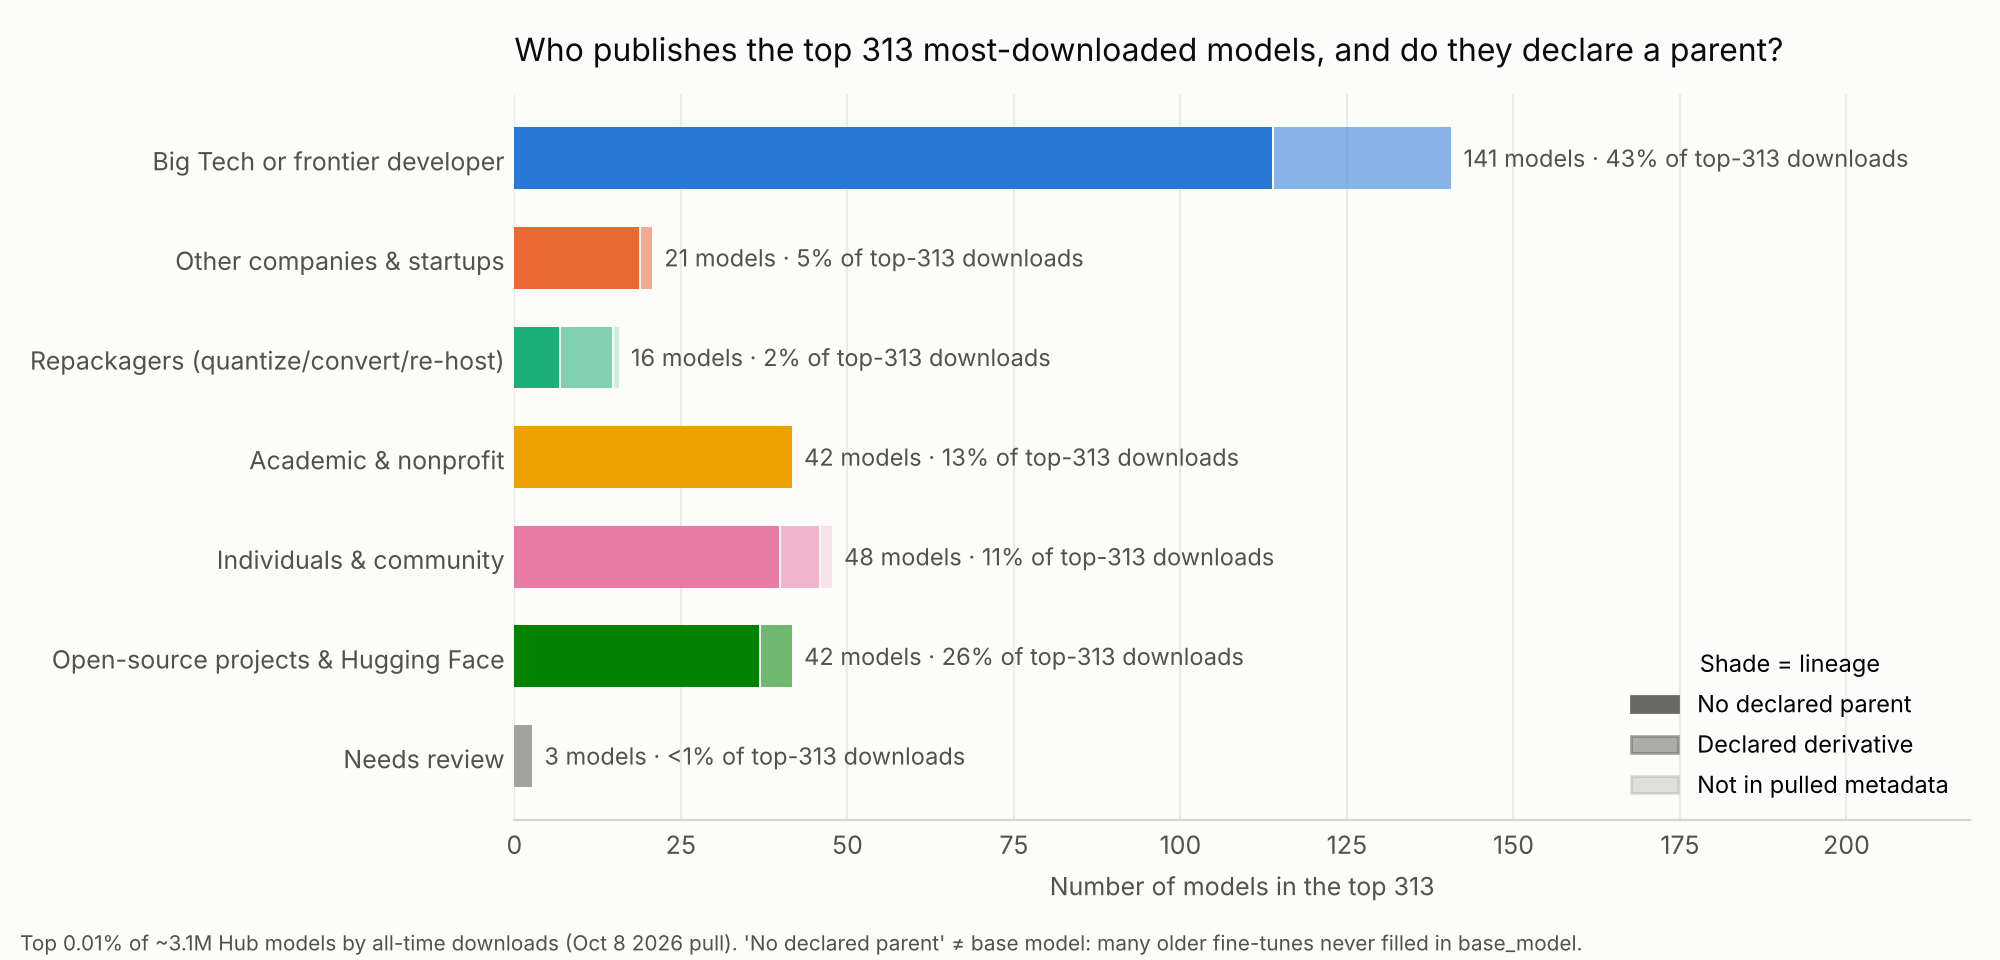

In [4]:
display(Image(f"{mla.OUT_DIR}/fig1_top{mla.TOP_N}_publishers.png", width=900))

**Reading this (Oct 8 2026 data):** most of the top 313 are older models, many from the BERT era. Only a small minority declare a parent, but "no declared parent" doesn't mean "base model": many are clearly fine-tunes that never filled in the field.

## 2. Where derivatives trace back to

In [5]:
res["reach"].style.format("{:.1%}")

,share_of_all_models_published,share_of_derivatives_rooted_in_their_models
Big Tech + frontier developer,2.3%,38.2%
"Big Tech, not frontier",0.4%,1.5%
"Frontier developer, not Big Tech",0.2%,6.4%
Other companies & startups,0.7%,10.6%
Repackagers (quantize/convert/re-host),7.4%,0.8%
Academic & nonprofit,2.4%,4.0%
Individuals & community,3.6%,10.8%
Open-source projects & Hugging Face,1.5%,1.8%
Needs review,0.5%,1.7%
Unlabeled (long tail),81.1%,24.3%


In [6]:
res["by_type"].style.format({"derivatives": "{:,.0f}", "derivative_downloads": "{:,.0f}",
                             "share_of_derivatives": "{:.1%}", "share_of_derivative_downloads": "{:.1%}"})

,derivatives,derivative_downloads,share_of_derivatives,share_of_derivative_downloads
root_type,,,,
Big Tech + frontier developer,"7,316","12,349,904,460",38.2%,82.1%
"Big Tech, not frontier",280,"48,966,249",1.5%,0.3%
"Frontier developer, not Big Tech","1,232","720,273,468",6.4%,4.8%
Other companies & startups,"2,029","788,736,686",10.6%,5.2%
Repackagers (quantize/convert/re-host),152,"47,368,267",0.8%,0.3%
Academic & nonprofit,759,"270,190,043",4.0%,1.8%
Individuals & community,"2,070","282,100,937",10.8%,1.9%
Open-source projects & Hugging Face,345,"231,202,224",1.8%,1.5%
Needs review,335,"20,526,867",1.7%,0.1%


In [7]:
# Each test on its own (they overlap)
res["per_test"].style.format("{:.1%}")

,share_of_derivatives,share_of_derivative_downloads
Big Tech (market cap >= $100B),39.6%,82.4%
Frontier developer (capability or compute),44.6%,86.9%
Either,46.1%,87.2%


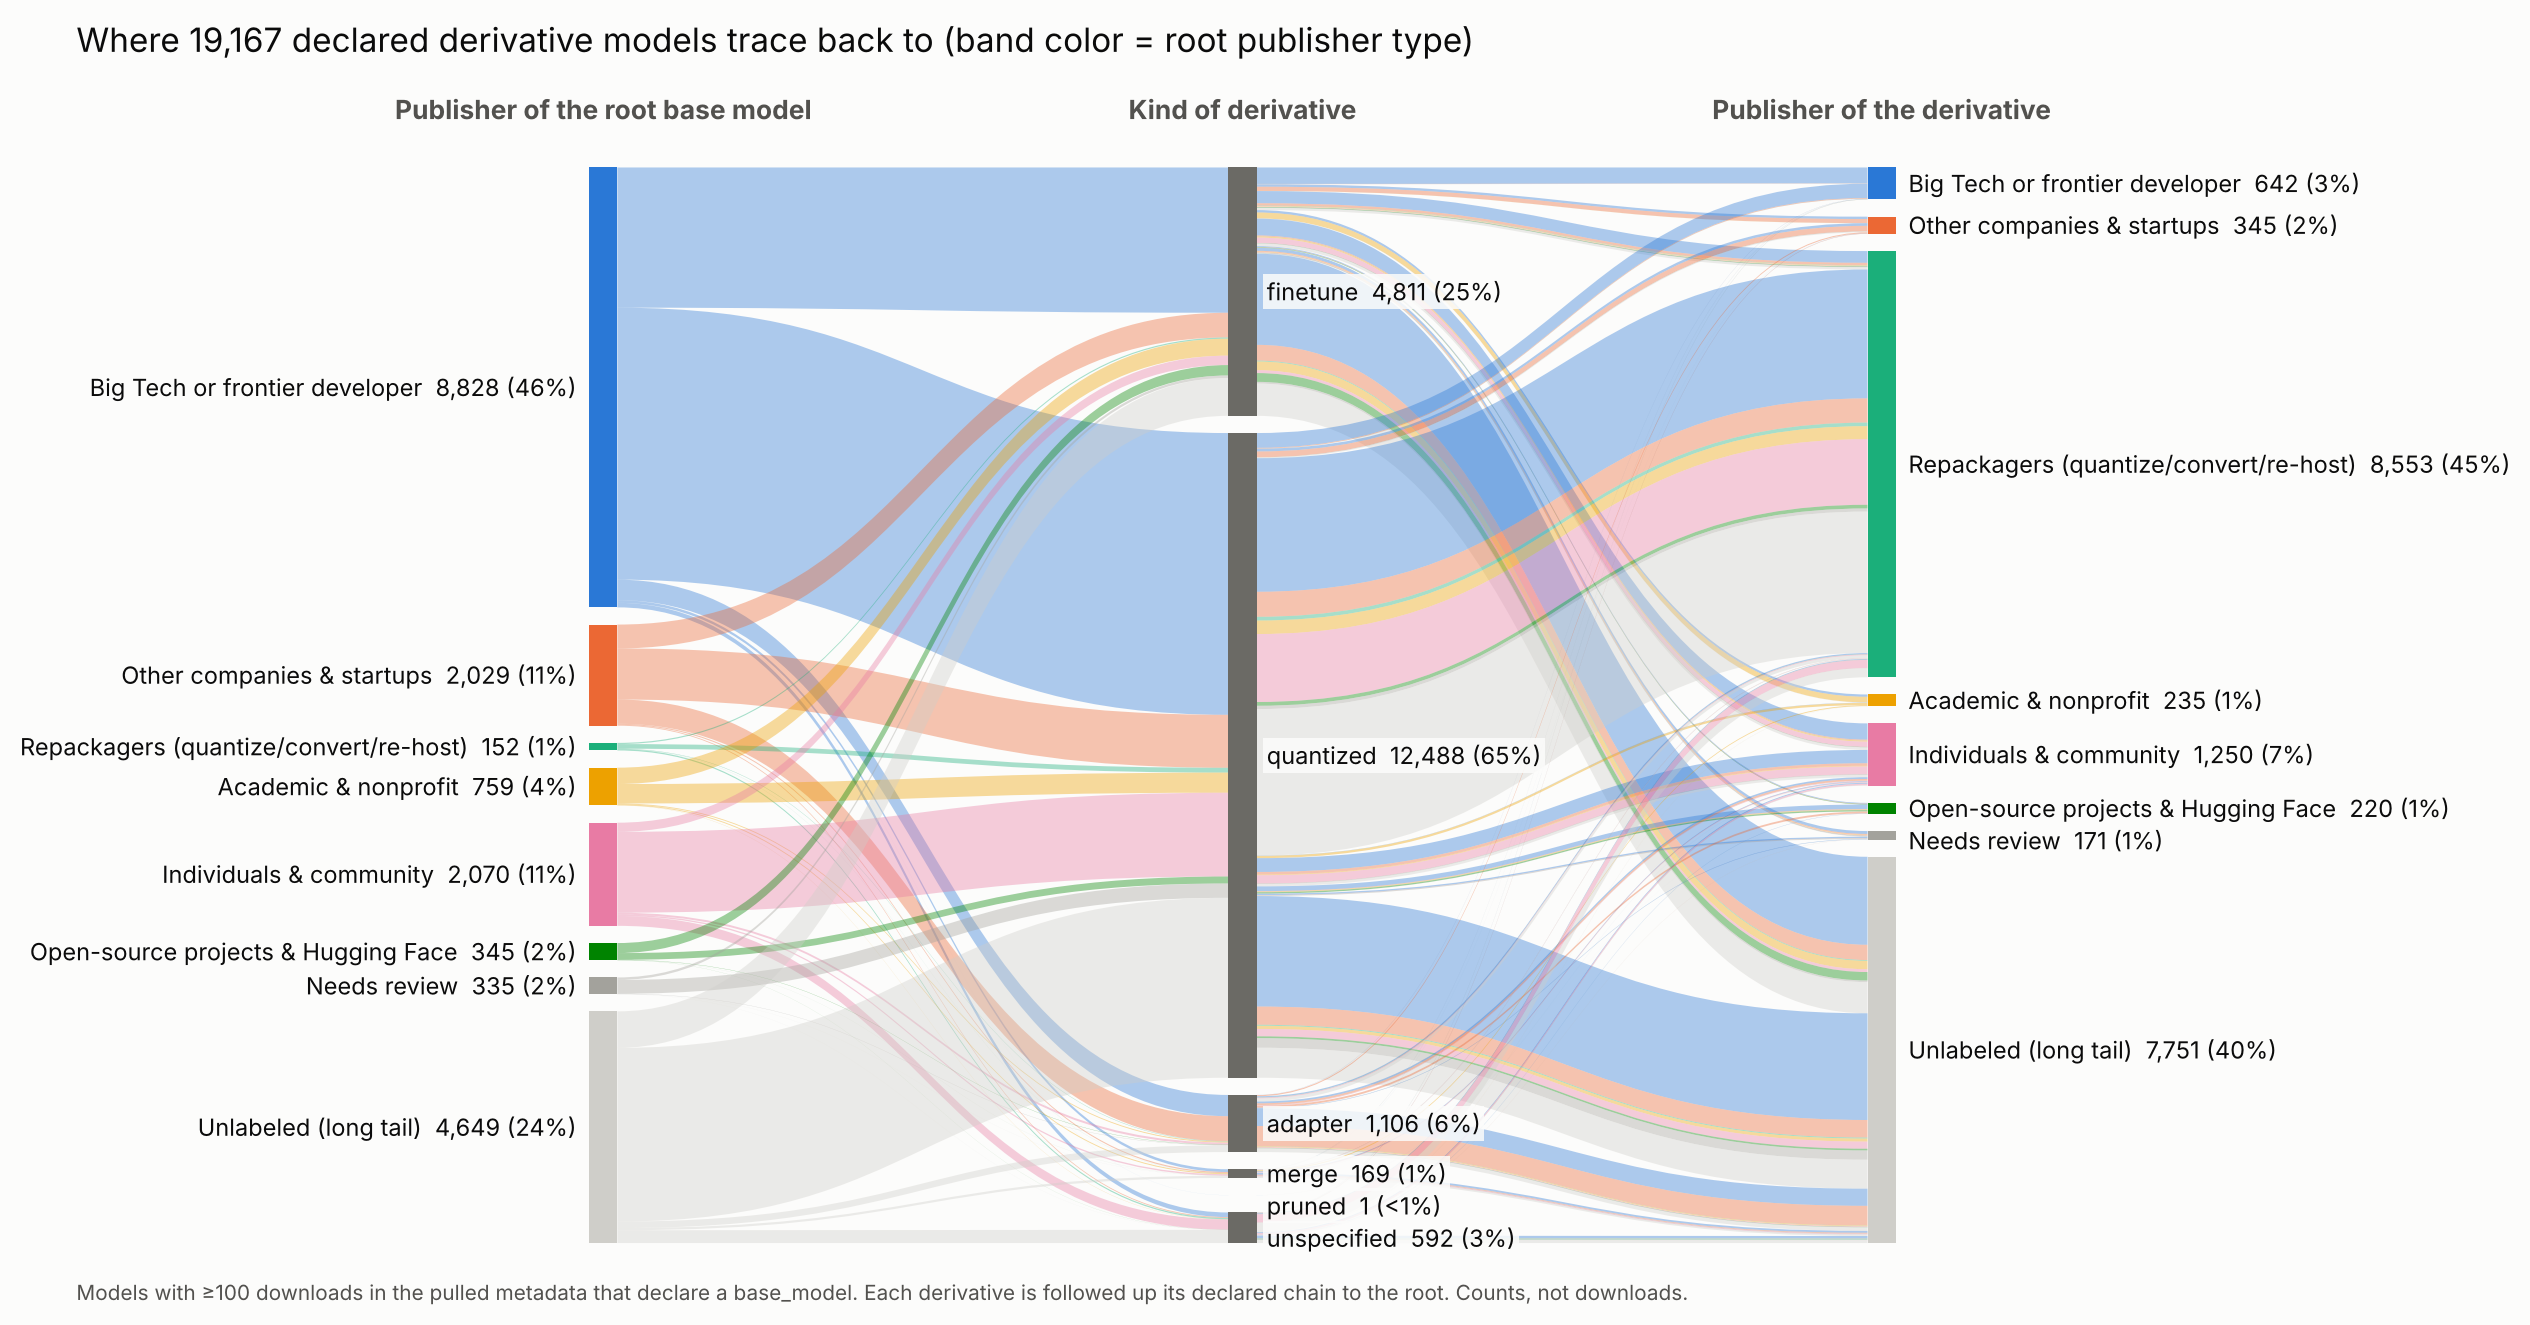

In [8]:
display(Image(f"{mla.OUT_DIR}/fig2_lineage_flow.png", width=1000))

**Reading this (Oct 8 2026 data):**
- **Five companies pass both tests: Google, Meta, Microsoft, NVIDIA and Alibaba.** Together they publish about 2% of models but are the root of 38% of all derivatives and 82% of derivative downloads.
- **Most derivatives are repackagings.** About 65% are quantizations and 25% are fine-tunes. Repackagers publish about 45% of all derivatives.

In [9]:
res["companies"].head(25).style.format({"derivatives": "{:,.0f}", "derivative_downloads": "{:,.0f}"}, na_rep="")

,derivatives,derivative_downloads,group,listing,market_cap_usd_bn,big_tech,capability_frontier,compute_frontier,frontier,hq_country
root_org,,,,,,,,,,
Alibaba,"4,520","3,789,845,727",Big Tech + frontier developer,public,272.28,y,y,y,y,CN
Google,"1,285","1,772,894,799",Big Tech + frontier developer,public,3490,y,y,y,y,US
Meta,897,"1,059,324,201",Big Tech + frontier developer,public,1560,y,y,y,y,US
Mistral AI,409,"322,956,788","Frontier developer, not Big Tech",private,,n,y,y,y,FR
OpenAI,353,"204,187,579","Frontier developer, not Big Tech",private,,n,y,y,y,US
DeepSeek,333,"143,694,027","Frontier developer, not Big Tech",private,,n,y,n,y,CN
Microsoft,333,"5,508,050,936",Big Tech + frontier developer,public,3940,y,n,y,y,US
Zhipu AI,286,"56,565,619",Other companies & startups,unverified,,n,n,n,n,CN
NVIDIA,281,"219,788,797",Big Tech + frontier developer,public,4506,y,n,y,y,US


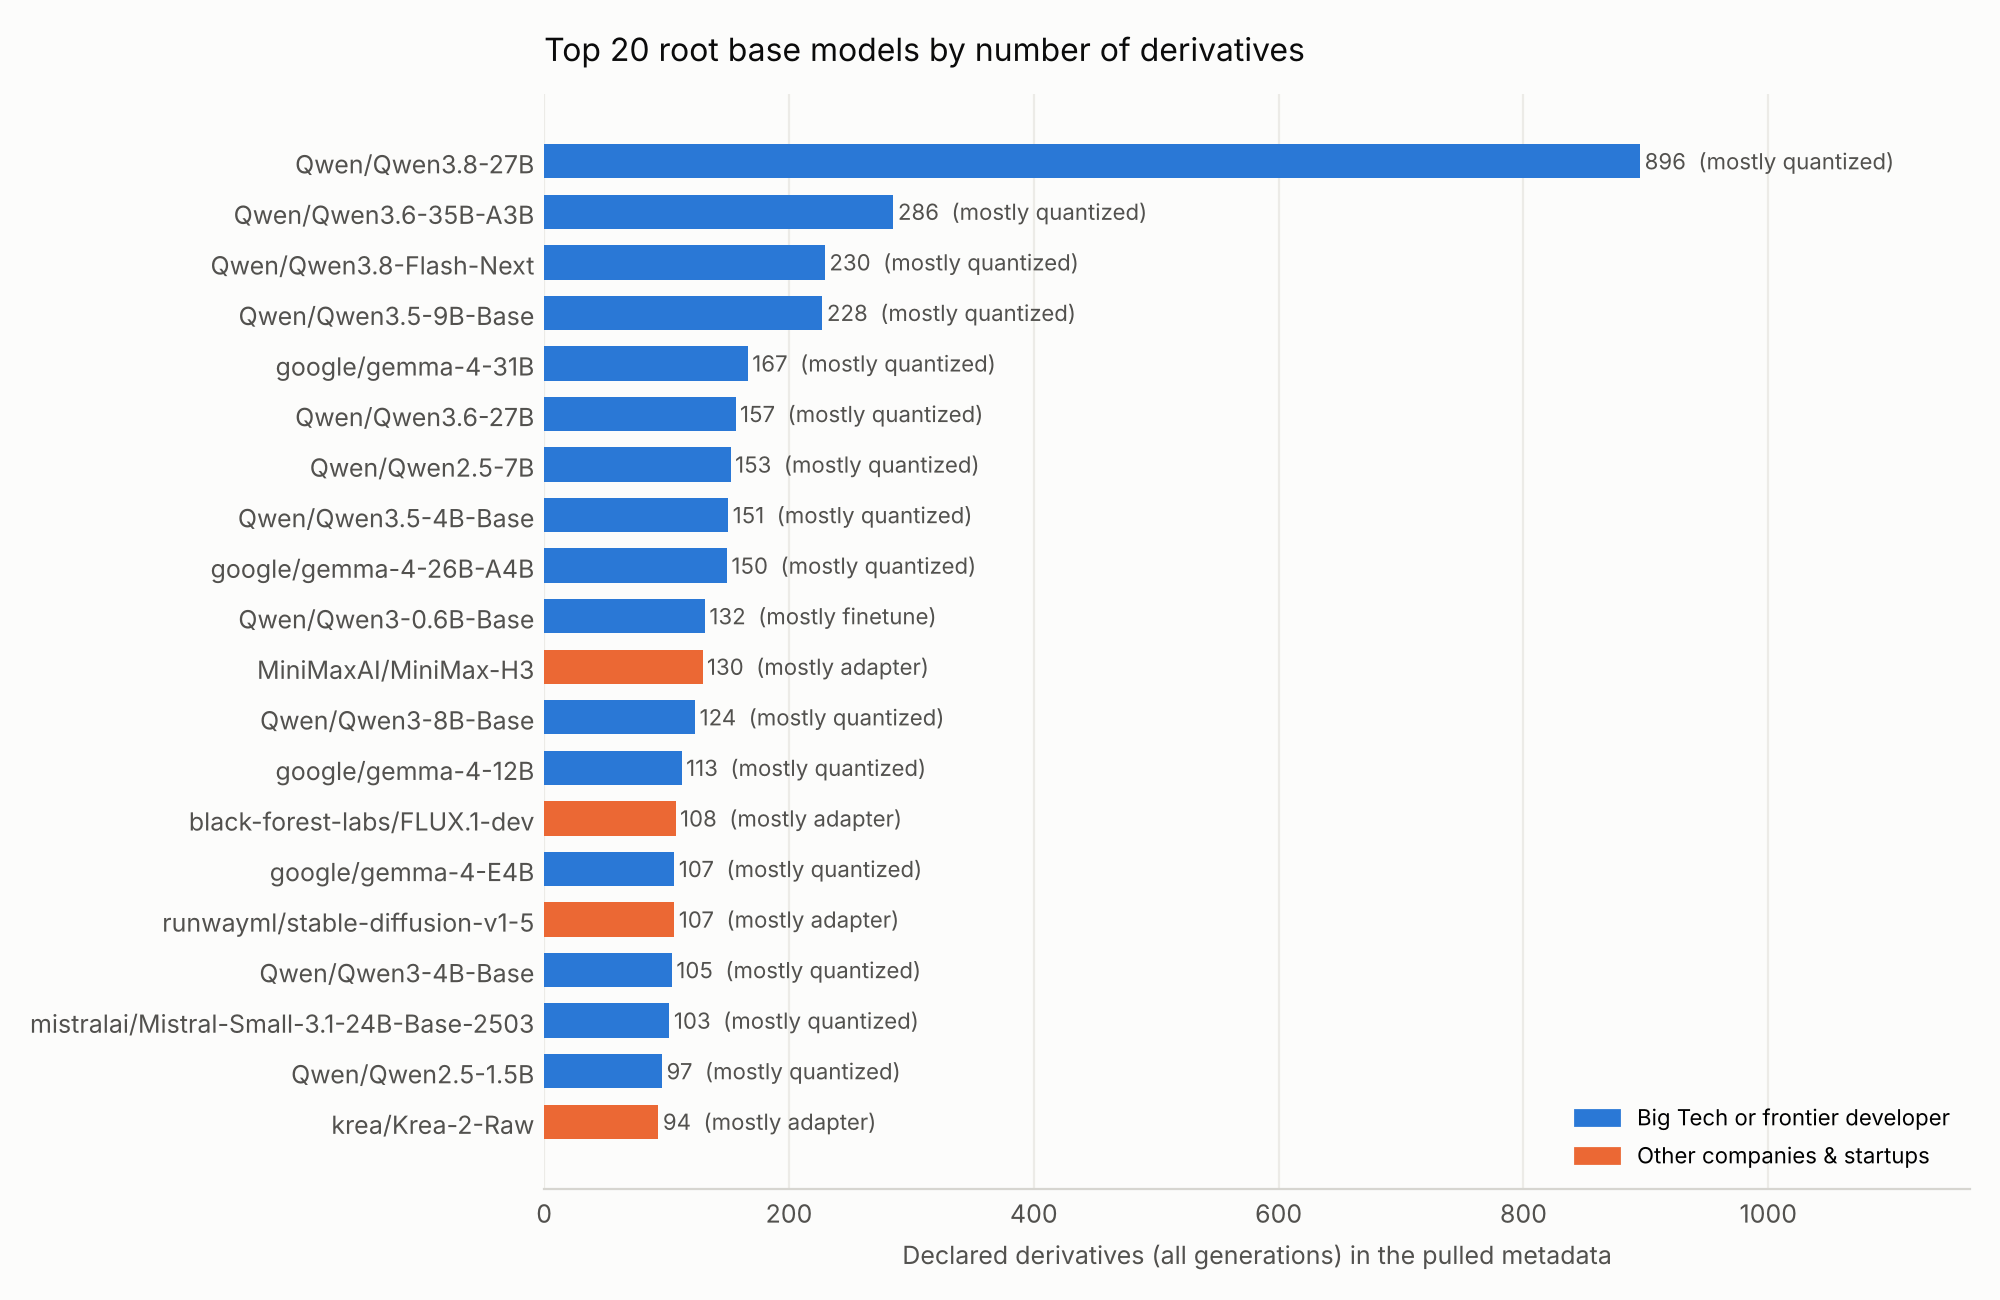

In [10]:
display(Image(f"{mla.OUT_DIR}/fig3_top_root_models.png", width=900))

## 2b. Total footprint: own models + all their derivatives

**What share of all Hugging Face downloads goes to a group's models, counting both the models it published itself and every derivative traced back to them?**

- **Own model downloads:** downloads of models the group published directly, e.g. `Qwen/Qwen3-8B` or `google-bert/bert-base-uncased`.
- **Derivative downloads (not own):** downloads of derivatives rooted in the group's models that someone else published, e.g. a community fine-tune or a GGUF copy of Qwen.
- **Total footprint:** the two added together. Each model counts once per group, so nothing is double-counted within a group.
- **Share of all Hub downloads:** the total footprint ÷ downloads of all ~3.1M models on the Hub.

**Groups can overlap.** A repackager's GGUF of Qwen counts toward both the Repackagers group (its publisher) and Alibaba's group (its root). Likewise, `all-MiniLM-L6-v2` counts for both Open-source projects & HF (its publisher, sentence-transformers) and Microsoft (its root). So the group shares add up to more than 100%.

In [11]:
print(f"All Hub downloads: {res['hub_downloads'] / 1e9:,.1f}B")
res["footprint_by_group"].style.format({"own_model_downloads": "{:,.0f}", "derivative_downloads_not_own": "{:,.0f}",
                                        "total_footprint": "{:,.0f}", "share_of_all_hub_downloads": "{:.1%}"})

All Hub downloads: 75.8B


,own_model_downloads,derivative_downloads_not_own,total_footprint,share_of_all_hub_downloads
Big Tech or frontier developer (combined),"28,591,389,686","9,383,830,900","37,975,220,586",50.1%
Big Tech + frontier developer,"21,604,183,640","8,991,236,865","30,595,420,505",40.4%
"Big Tech, not frontier","1,929,052,407","23,622,417","1,952,674,824",2.6%
"Frontier developer, not Big Tech","5,058,153,639","400,466,768","5,458,620,407",7.2%
Other companies & startups,"3,962,986,344","626,229,460","4,589,215,804",6.1%
Repackagers (quantize/convert/re-host),"3,734,814,573","9,205,963","3,744,020,536",4.9%
Academic & nonprofit,"8,381,760,408","147,980,977","8,529,741,385",11.3%
Individuals & community,"6,670,708,999","98,840,400","6,769,549,399",8.9%
Open-source projects & Hugging Face,"15,003,508,089","155,669,966","15,159,178,055",20.0%
Needs review,"776,367,497","16,053,390","792,420,887",1.0%


In [12]:
res["footprint_by_company"].head(15).style.format({"own_model_downloads": "{:,.0f}", "derivative_downloads_not_own": "{:,.0f}",
                                                   "total_footprint": "{:,.0f}", "share_of_all_hub_downloads": "{:.1%}"})

,own_model_downloads,derivative_downloads_not_own,total_footprint,share_of_all_hub_downloads,group
Google,"7,852,327,007","1,363,631,710","9,215,958,717",12.2%,Big Tech + frontier developer
Microsoft,"2,776,003,454","5,386,016,409","8,162,019,863",10.8%,Big Tech + frontier developer
Meta,"6,446,861,706","779,607,266","7,226,468,972",9.5%,Big Tech + frontier developer
Alibaba,"4,024,299,958","1,398,515,997","5,422,815,955",7.2%,Big Tech + frontier developer
OpenAI,"4,190,074,441","81,286,352","4,271,360,793",5.6%,"Frontier developer, not Big Tech"
Amazon,"1,220,377,057","27,572","1,220,404,629",1.6%,"Big Tech, not frontier"
NVIDIA,"504,691,515","175,612,614","680,304,129",0.9%,Big Tech + frontier developer
DeepSeek,"396,761,630","109,400,878","506,162,508",0.7%,"Frontier developer, not Big Tech"
Mistral AI,"322,399,898","167,956,124","490,356,022",0.6%,"Frontier developer, not Big Tech"
Salesforce,"244,616,949","2,574,788","247,191,737",0.3%,"Big Tech, not frontier"


**Reading this (Oct 8 2026 data):**
- **Big Tech or frontier developers' models and their derivatives account for about half of all Hugging Face downloads** (≈50%).
- **The five companies that pass both tests account for ≈40%:** Google, Meta, Microsoft, NVIDIA and Alibaba.
- **Microsoft is the clearest case of reach through derivatives.** Most of its footprint comes from other people's derivatives of its models, largely through `all-MiniLM-L6-v2`. Google, Meta and OpenAI get most of theirs from their own uploads.

## 3. Effect of the documented corrections

The biggest correction is `all-MiniLM-L6-v2`, the most-downloaded model on the Hub (~4B downloads). It's a fine-tune of `nreimers/MiniLM-L6-H384-uncased`, whose card says it's *"a 6 layer version of microsoft/MiniLM-L12-H384-uncased by keeping only every second layer."* The metadata never records that link, so without the correction an individual's account gets the credit.

In [13]:
res["effect"].style.format("{:.1%}")

,share_of_derivatives_metadata_only,share_of_derivatives_with_corrections,share_of_derivative_downloads_metadata_only,share_of_derivative_downloads_with_corrections
root_type,,,,
Big Tech + frontier developer,37.9%,38.2%,54.1%,82.1%
"Big Tech, not frontier",1.5%,1.5%,0.3%,0.3%
"Frontier developer, not Big Tech",6.4%,6.4%,4.8%,4.8%
Other companies & startups,10.6%,10.6%,5.3%,5.2%
Repackagers (quantize/convert/re-host),0.8%,0.8%,0.3%,0.3%
Academic & nonprofit,4.0%,4.0%,1.8%,1.8%
Individuals & community,11.1%,10.8%,29.7%,1.9%
Open-source projects & Hugging Face,1.8%,1.8%,1.5%,1.5%
Needs review,1.7%,1.7%,0.1%,0.1%


## Note: the size test is US-centric

The market-cap test favors American companies:

- **Most companies that pass it are US-based.** The exceptions are Alibaba, Tencent and Prosus.
- **Market cap partly measures the stock market a company lists on.** US exchanges are deeper and value companies more highly, so a company of the same size is often worth less if it's listed in Hong Kong, Seoul or Europe.
- **Many leading non-US AI developers are private, so they can't pass by definition.** Examples: ByteDance, Huawei, DeepSeek and Moonshot. Several are also state-linked.
- **Borderline cases sit right on the line.** Xiaomi ($99.1B) and Snowflake ($97.3B) fall just short.

The size test therefore measures "large US-style public tech company" more than "economically powerful AI developer". The frontier tests are more country-neutral. For any comparison between countries, use the frontier tests, or treat private valuations as a sensitivity check.

In [14]:
orgs = res["orgs"]
pd.crosstab(orgs["hq_country"], [orgs["big_tech"], orgs["frontier"]]).rename_axis(index="HQ", columns=["Big Tech", "Frontier"])

Big Tech  n     y   
Frontier  n  y  n  y
HQ                  
CA        1  0  0  0
CN        6  4  1  1
FR        0  1  0  0
KR        2  0  0  0
NL        0  0  1  0
US        2  3  6  4

## Note: Chinese developers and the frontier tests

**On compute alone, DeepSeek, Zhipu AI and MiniMax all fail**, even though they're widely treated as leading developers. Their largest recorded training runs fall just short of 10^25 FLOP: DeepSeek-V4-Pro at 9.7×10^24 and Zhipu GLM-5 at 6.84×10^24, with no MiniMax model ≥10^25 recorded. These labs are known for reaching frontier performance with less compute. That's the main reason the capability test is the primary one.

**With the capability test:**
- **DeepSeek passes.** DeepSeek-R1 (Jan 2025) was 2.5 ECI points behind the frontier.
- **Zhipu AI just misses.** Its closest was GLM-5.3 (Aug 2026), 7.5 points behind.
- **MiniMax misses.** MiniMax-M3 (Jun 2026) was 15 points behind.
- **Both still fail the size test**, since they're private or listed below $100B. So they count as "Other companies & startups".

Other Chinese developers do pass. Alibaba is both Big Tech and frontier, and it's the root of the most derivatives of any company. Tencent is Big Tech, and ByteDance, Huawei, Moonshot and DeepSeek are frontier.

In [15]:
# Sensitivity: also count Zhipu AI and MiniMax as frontier developers
cn3 = kids["root_org"].isin(["Zhipu AI", "MiniMax"])
frontier = kids["root_type"].isin([mla.BIG_FRONTIER, mla.FRONTIER_ONLY])
d = kids["downloads"].sum()
pd.DataFrame({
    "share_of_derivatives": [frontier.mean(), (frontier | cn3).mean()],
    "share_of_derivative_downloads": [kids.loc[frontier, "downloads"].sum() / d, kids.loc[frontier | cn3, "downloads"].sum() / d],
}, index=["Frontier tests as defined", "+ Zhipu AI, MiniMax"]).style.format("{:.1%}")

,share_of_derivatives,share_of_derivative_downloads
Frontier tests as defined,44.6%,86.9%
"+ Zhipu AI, MiniMax",47.1%,87.9%


## Caveats (read before citing numbers)

1. **"No declared parent" does not mean "base model".** Many fine-tunes never filled in `base_model` (e.g. `jonatasgrosman/wav2vec2-large-xlsr-53-*`, which are fine-tunes of Meta's XLSR), so derivative counts are a **lower bound**.
2. **Relation labels are inferred by the Hub and can be wrong.**
3. **Coverage is only models with ≥100 downloads.**
4. **The company tests are snapshots.** Market caps move daily, new models can cross 10^25 FLOP, and the capability leaderboard is updated as models are evaluated. Re-check `org_classification.csv` and refresh `eci_scores_snapshot.csv` each quarterly run. Epoch's compute figures are estimates (some marked speculative), and ECI scores carry confidence intervals.
5. **The 5-point capability gap is a judgment call.** At 4 points Alibaba drops out; at 6, Moonshot gets in through capability as well (it already passes on compute). The rule and its threshold are set in `model_lineage_analysis.py` (`CAPABILITY_GAP_ECI`).
6. **Download counts include automated pulls.** Hugging Face counts every fetch, including CI pipelines, servers and containers that download a model each time they run. So a high count partly means "a default that tools pull automatically", not only "many people chose it". This matters most for embedding models like `all-MiniLM-L6-v2`, so treat every downloads-based share (derivative downloads, total footprint) as a measure of usage, not of the number of users.
7. **Hand labels need review.** Check rows marked `needs_review` in `author_types.csv`. Add a correction only with a public source.